# Dimensionality Reduction

In this exercise, we will use principal component analysis to perform dimensionality reduction on our dataset. Recall that the `netml` library has mechanisms to extract a wide range of statistics from traffic flows. We will start with those (an N-dimensional feature set), and then use principal component analysis to reduce the dimensionality of the data.

In [1]:
import logging
logging.getLogger("scapy.runtime").setLevel(logging.ERROR)

from netml.pparser.parser import PCAP

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline

## Load the Packet Capture Files

Load the Log4j and HTTP packet capture files and extract features from the flows. You can feel free to compute features manually, although it will likely be more convenient at this point to use the `netML` library.

In [2]:
http_pcap = PCAP("data/http.pcap")
log4j_pcap = PCAP("data/log4j.pcap")


## Convert the Packet Capture Into Flows

Find the function in `netml` that converts the pcap file into flows. Examing the resulting data structure. What does it contain?

In [3]:
http_pcap.pcap2flows()
log4j_pcap.pcap2flows()

# `.flows` is a list of (flow_id, packets) tuples:
#   flow_id  -> (src_ip, dst_ip, src_port, dst_port, proto)
#   packets  -> list of scapy packets belonging to that flow
fid, packets = http_pcap.flows[0]
print(fid)
print(len(packets), "packets in this flow")
print(packets[0].summary())


('192.168.1.58', '35.186.224.43', 57256, 443, 6)
4 packets in this flow
Ether / IP / TCP 192.168.1.58:57256 > 35.186.224.43:https PA / Raw


## Explore the Flows

How many flows are in each of these pcaps? (Use the `netml` library output to determine the size of each data structure.)

In [4]:
print(f"http flows:  {len(http_pcap.flows)}")
print(f"log4j flows: {len(log4j_pcap.flows)}")


http flows:  291
log4j flows: 4795


## Try Your Data on a Tree-Based Model

You should now have data that can be input into a model with scikit-learn. Import the scikit-learn package (`sklearn`) and a classification model of your choice to test that you can train your model with the above data. 

Hint: The function you want to call is `fit`.

Before applying dimensionality reduction, we can first build on our understanding of classifiers from past notebooks to see which features may be most important. 

Let's try training a model first with a **Decision Tree**, then with a RandomForest classifier, which gives us nice ways of exploring feature importance.

### Decision Tree

Train a decision tree below.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# STATS gives a fixed-length, 12-value feature vector per flow:
# duration, pkts/sec, bytes/sec, mean, std, q1, median, q3, min, max, num_pkts, num_bytes
http_pcap.flow2features("STATS", fft=False, header=False)
log4j_pcap.flow2features("STATS", fft=False, header=False)

X_http = http_pcap.features
X_log4j = log4j_pcap.features

y_http = np.zeros(len(X_http))     # non-attack
y_log4j = np.ones(len(X_log4j))    # attack

X = np.vstack([X_http, X_log4j])
y = np.concatenate([y_http, y_log4j])

print(X.shape, y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)


(5086, 12) (5086,)


DecisionTreeClassifier(max_depth=4, random_state=42)

### Visualize the Resulting Model

Below is an example showing how the resulting decision tree can be visualized. We kept the number of features small above to make visualization quick. You may need to install some dependencies (pydotplus, plus the graphviz executable, to get this cell to run.

To install graphviz on a Mac, for example, you can use a tool like Homebrew (e.g., brew install graphviz).

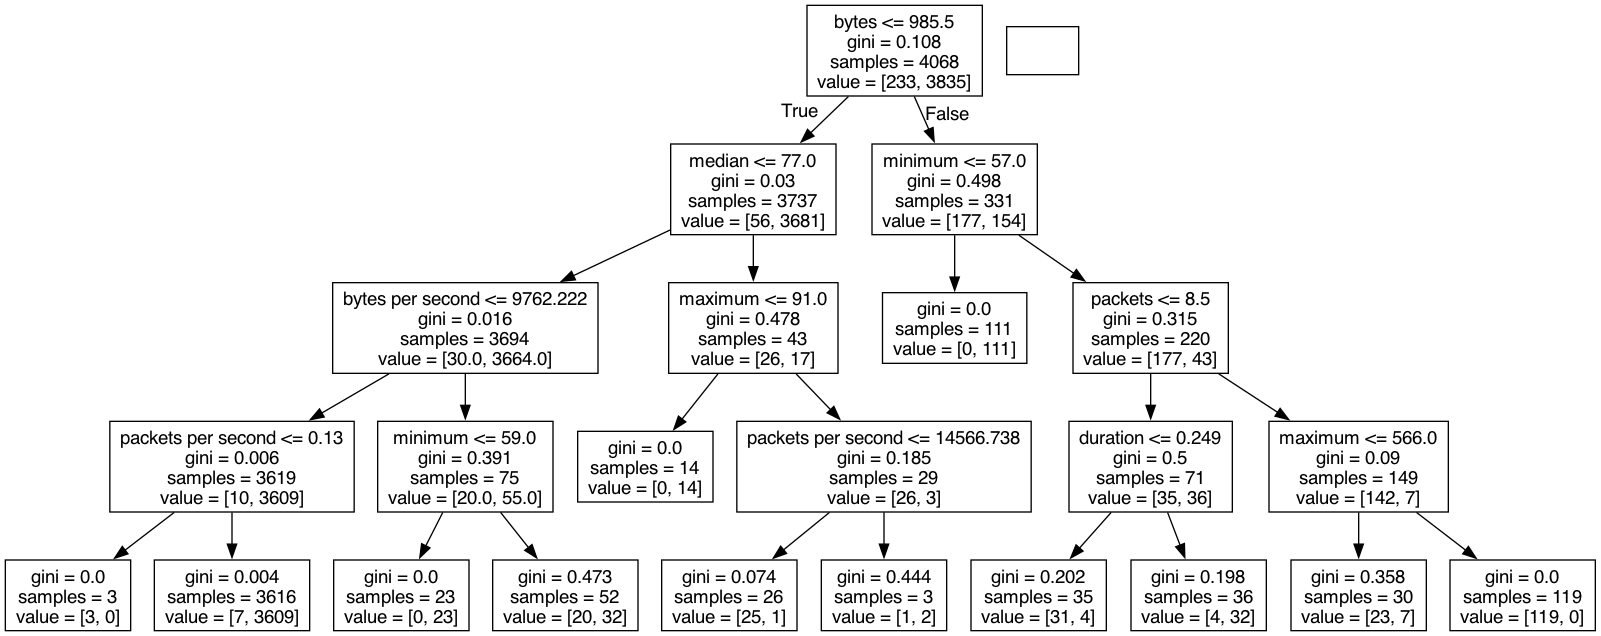

In [7]:
from sklearn import tree
import pydotplus
from IPython.display import Image

labels = ['duration', 'packets per second', 
          'bytes per second', 
          'mean', 'standard deviation', 
          '25', 'median', '75', 
          'minimum', 'maximum',
          'packets','bytes']

dot_data = tree.export_graphviz(dt, out_file=None, feature_names=labels)

graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

### Evaluate the Model

We can look at the accuracy of this simple model using a K-Fold cross validation and accuracy score.

In [8]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import accuracy_score

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores_dt = cross_val_score(dt, X, y, cv=kfold)
print(f"decision tree cross-val accuracy: {scores_dt.mean():.4f} (+/- {scores_dt.std():.4f})")

y_pred_dt = dt.predict(X_test)
print(f"decision tree test accuracy:      {accuracy_score(y_test, y_pred_dt):.4f}")


decision tree cross-val accuracy: 0.9827 (+/- 0.0031)
decision tree test accuracy:      0.9823


## Random Forest Classifiers
Random forest improves on a decision tree classifier using an ensemble learning method called bagging. In a random forest, 

1. many decision trees are trained. Each tree receives a boostrapped sample of observations, and
2. each node only considers a subset of the features when determining the best split.

The balanced mode, which we use below, uses the values of y to automatically adjust weights inversely proportional to class frequencies in the input data as n_samples / (n_classes * np.bincount(y)).

### Train a Random Forest Classifier

Train a random forest classifier using the same approach as you used for the decision tree.

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', random_state=42)

### Evaluate Your Classifier

Evaluate your random forest classifier using the same evaluation method as for the decision tree.  Does accuracy improve?

In [10]:
scores_rf = cross_val_score(rf, X, y, cv=kfold)
print(f"random forest cross-val accuracy: {scores_rf.mean():.4f} (+/- {scores_rf.std():.4f})")

y_pred_rf = rf.predict(X_test)
print(f"random forest test accuracy:      {accuracy_score(y_test, y_pred_rf):.4f}")


random forest cross-val accuracy: 0.9955 (+/- 0.0015)
random forest test accuracy:      0.9941


## Feature Importance

One of the powerful aspects of a random forest classifier is that it is easy to plot and understand feature importance. The feature_importances_ data structure maintains these relative feature importance values, which we can plot and visualize.

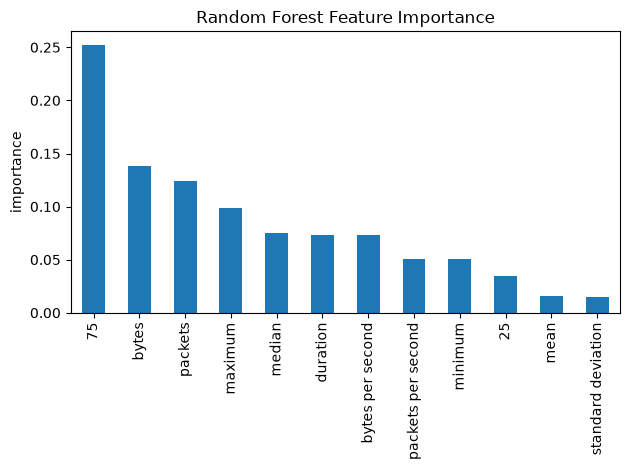

In [11]:
importances = pd.Series(rf.feature_importances_, index=labels)
importances = importances.sort_values(ascending=False)

importances.plot(kind="bar")
plt.ylabel("importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


## Dimensionality Reduction

One way to reduce the dimensionality of a dataset is with a technique called principal components analysis (PCA). PCA is a linear transformation that maps the points into a space where the lower dimensions are orthogonal and also capture the highest variance in the dataset.

So, the first principal component (PC1) is a vector that is oriented in the direction that captures the highest variance in the dataset. You can think of this as the single dimension that has the most information in the dataset. PC2 captures the next highest variance, in the direction that is orthogonal to PC2, and so forth.

There are many applications of PCA, but one application is the visualization of a high-dimension dataset, since PCA is just a transformation of the data that does not inherently lose information. When we only project into the top two dimensions, some information is lost (whatever is in the lower principal compoenents), but we can visualize the data in terms of the two dimensions that capture the most "information" (i.e., variance) in the dataset.

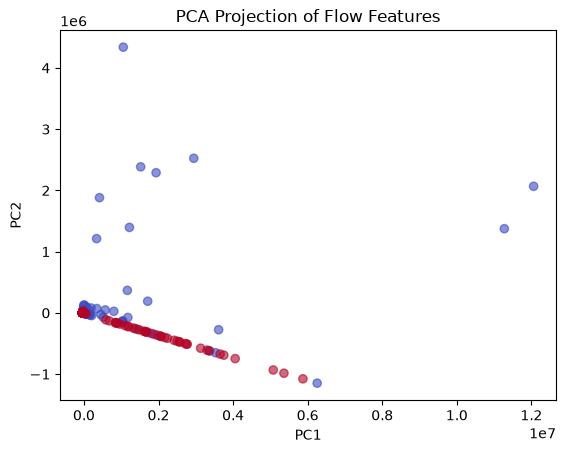

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", alpha=0.6)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection of Flow Features")
plt.show()


### Understanding Explained Variance

The first principal components will capture msot of the variance. We can look at the explained variance ratio to understand how much variance each of those principal components captures, which will give us a sense of where we might be able to cut off this data, particularly if we look at cumulative explained variance.

In [13]:
pca.explained_variance_ratio_

array([0.91489261, 0.08507621])

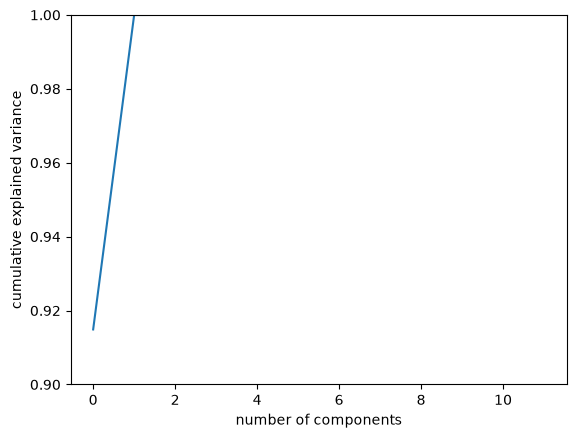

In [14]:
pca = PCA(n_components=12)
pca.fit(X)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.ylim([0.9,1])
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance');

### Understanding the Top Principal Components

If we look at the top principal component, we can also see that it is a linear combination of our original features, which has a disproportionate "amount" of the 25th percentile of packet size.

In [15]:
pca.components_[0]


array([-1.11131659e-06,  7.11715178e-03,  9.83734774e-01,  8.89456135e-05,
       -2.89616810e-07,  1.03849723e-04,  1.05013360e-04,  1.02492726e-04,
        3.33622642e-06,  5.35074914e-05,  1.23282170e-04,  1.79485885e-01])

In [16]:
# Sort in descending order
indices = np.argsort(pca.components_[0])[::-1]

# Sort the labels in a corresponding fashion
names = [labels[i] for i in indices]
names

['bytes per second',
 'bytes',
 'packets per second',
 'packets',
 'median',
 '25',
 '75',
 'mean',
 'maximum',
 'minimum',
 'standard deviation',
 'duration']

### Evaluate the Lower Dimension Model

Evaluate the accuracy of the lower dimensionality model trained on the random forest classifier in the same fashion as above. What happens to the accuracy? Why?

What might be a good reason to reduce the dimensionality of the dataset?

The accuracy goes a little bit down, because there is less information for the model to train on. However, the accuracy didn't dip to a level that makes the model unreliable at detecting the attacks. Reducing dimensionality can help a lot with compute speed, and human visualization, especially in the form of PCA. If done in a way that is well-labeled, you can easily see which features have the most variance in a data set, it's just difficult to do by hand.

In [17]:
# Reduce to the top 2 principal components (as used for visualization above)
# and retrain/evaluate the random forest classifier on the lower-dimensional data.
pca_reduced = PCA(n_components=2)
X_reduced = pca_reduced.fit_transform(X)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reduced, y, test_size=0.2, stratify=y, random_state=42
)

rf_reduced = RandomForestClassifier(class_weight="balanced", random_state=42)
rf_reduced.fit(X_train_r, y_train_r)

y_pred_reduced = rf_reduced.predict(X_test_r)
print(f"random forest (2 PCA components) test accuracy:      {accuracy_score(y_test_r, y_pred_reduced):.4f}")

scores_reduced = cross_val_score(rf_reduced, X_reduced, y, cv=kfold)
print(f"random forest (2 PCA components) cross-val accuracy: {scores_reduced.mean():.4f} (+/- {scores_reduced.std():.4f})")


random forest (2 PCA components) test accuracy:      0.9735
random forest (2 PCA components) cross-val accuracy: 0.9768 (+/- 0.0025)
